# 线性回归笔记

## 1. 回归与线性回归

**回归（regression）** 是一类对目标变量与一个或多个特征之间的关系建模的方法（是一大类监督学习（Supervised Learning）方法的统称，而不是某一个单一的算法），常用于预测数值。例如，可以根据房屋面积和房龄预测成交价。

**线性回归（linear regression）** 用特征的加权和加上截距来预测目标值。它的核心假设是，给定特征向量 $x$ 时，目标变量 $y$ 的条件均值可以写成

$$
\mathbb{E}[y \mid x] = w^\top x + b.
$$

以房价为例，面积和房龄相同的房屋可以有不同的成交价。模型用同一个预测值估计这类房屋的平均成交价。

## 2. 基础术语

| 术语 | 含义 | 房价示例 |
|---|---|---|
| 训练集（training set） | 用于拟合模型参数的一组样本 | 用于训练的房屋成交记录 |
| 样本（sample）或数据点（data point） | 一条观测记录，在表格中通常对应一行 | 某套房屋的一条成交记录 |
| 特征（feature）或协变量（covariate） | 用于预测目标的输入变量 | 房屋面积、房龄 |
| 标签（label）或目标（target） | 目标是要预测的变量，训练样本给出了它的观测值 | 实际成交价 |
| 模型参数（model parameters） | 通过训练数据估计的量 | 面积和房龄各自的权重，以及截距 |

## 3. 单个样本的预测

假设一个样本有 $d$ 个特征。用 $x = (x_1, \dots, x_d)^\top \in \mathbb{R}^d$ 表示特征向量，$w = (w_1, \dots, w_d)^\top \in \mathbb{R}^d$ 表示权重向量，$b \in \mathbb{R}$ 表示偏置。给定一组参数，预测值 $\hat{y}$ 可以写成

$$
\hat{y}
= w_1 x_1 + \cdots + w_d x_d + b
= w^\top x + b.
$$

其中，$w^\top x$ 是权重向量与特征向量的点积。在房价模型中，上式可以写成

$$
\widehat{\mathrm{price}}
= w_{\mathrm{area}} \cdot \mathrm{area}
+ w_{\mathrm{age}} \cdot \mathrm{age}
+ b.
$$

- **权重（weight）** $w_j$ 表示在其他特征保持不变时，第 $j$ 个特征每增加一个单位，预测值的变化量。例如，面积以平方米计、价格以元计时，$w_{\mathrm{area}}$ 表示房龄相同的情况下，面积每增加一平方米，预测总价变化多少元。
- **偏置（bias）或截距（intercept）** $b$ 表示所有特征都为零时的预测值。即使“面积为零的房屋”没有实际意义，保留截距仍然允许模型调整整体预测水平。令 $b = 0$ 则会强制模型经过原点。

从数学上说，$x \mapsto w^\top x$ 是线性变换。加上偏置后的映射 $x \mapsto w^\top x + b$ 称为**仿射变换（affine transformation）**。

## 4. 观测值、噪声与残差

在线性回归的条件均值假设下，实际观测值可以写成

$$
y = w^\top x + b + \varepsilon,
\qquad
\mathbb{E}[\varepsilon \mid x] = 0.
$$

这里的 $\varepsilon$ 是**噪声**，表示一次观测相对真实条件均值的偏离。$\mathbb{E}[\varepsilon \mid x] = 0$ 表示给定 $x$ 时，这些偏离平均为零。

**用最小二乘法拟合参数无须假设噪声服从正态分布。** 正态性是进行某些统计推断时采用的额外假设。

模型拟合后，可以用实际值 $y_i$ 和预测值 $\hat{y}_i$ 计算第 $i$ 个样本的**残差（residual）**：

$$
e_i = y_i - \hat{y}_i.
$$

噪声相对于真实条件均值定义，通常无法直接观测。残差相对于已拟合模型的预测值定义，可以直接计算。

## 5. 多个样本的矩阵表示

设训练集有 $n$ 个样本，每个样本有 $d$ 个特征。将第 $i$ 个样本的特征向量转置后放在第 $i$ 行，得到**特征矩阵**，也称**设计矩阵**：

$$
X =
\begin{bmatrix}
x_{11} & \cdots & x_{1d} \\
\vdots & \ddots & \vdots \\
x_{n1} & \cdots & x_{nd}
\end{bmatrix}
\in \mathbb{R}^{n \times d}.
$$

其中，$x_{ij}$ 表示第 $i$ 个样本的第 $j$ 个特征。将所有样本的预测值排成列向量 $\hat{\mathbf{y}} \in \mathbb{R}^n$，就得到

$$
\hat{\mathbf{y}} = Xw + b\mathbf{1}_n.
$$

这里，$Xw \in \mathbb{R}^n$，$\mathbf{1}_n \in \mathbb{R}^n$ 是全 1 向量。加上 $b\mathbf{1}_n$，就是给每个样本的预测值加上同一个截距。代码中常写为 `X @ w + b`，由广播机制完成这一步。

## 6. 训练目标与参数求解

训练模型需要确定两件事：用什么标准衡量拟合误差，以及怎样找到使误差最小的参数。

### 衡量拟合误差

常用的损失函数是**均方误差（mean squared error，MSE）**。记第 $i$ 个样本的特征向量为 $x_i$，将每个样本的预测误差平方后取平均，得到

$$
L(w, b)
= \frac{1}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i)^2
= \frac{1}{n} \sum_{i=1}^{n} (w^\top x_i + b - y_i)^2.
$$

### 求解模型参数

选择使损失函数最小的权重和截距，得到参数估计值 $\hat{w}$ 和 $\hat{b}$：

$$
(\hat{w}, \hat{b}) = \arg\min_{w, b} L(w, b).
$$

这就是**普通最小二乘法（ordinary least squares，OLS）**的目标。由于训练样本数 $n$ 固定，最小化均方误差与最小化残差平方和会得到相同的解。求解时，既可以使用线性代数方法直接求解，也可以使用梯度下降等迭代方法。

训练完成后，对新样本 $x_{\mathrm{new}}$ 的预测为

$$
\hat{y}_{\mathrm{new}} = \hat{w}^\top x_{\mathrm{new}} + \hat{b}.
$$

In [28]:
%matplotlib inline

import math
import time
import torch
import random
import numpy as np
from d2l import torch as d2l
from matplotlib_inline.backend_inline import set_matplotlib_formats

def use_svg_display():
    set_matplotlib_formats('svg')

d2l.use_svg_display = use_svg_display

In [29]:
n = 1000
a = torch.ones([n])
b = torch.ones([n])

In [30]:
class Timer: #@save
    "记录多次运行时间"
    def __init__(self):
        self.times = []
        self.start()

    def start(self):
        "启动计时器"
        self.tik = time.time()

    def stop(self):
        "停止计时器并将时间记录在列表中"
        self.times.append(time.time() - self.tik)
        return self.times[-1]

    def avg(self):
        "返回平均时间"
        return sum(self.times) / len(self.times)

    def sum(self):
        "返回时间总和"
        return sum(self.times)

    def cumsum(self):
        "返回累计时间"
        return np.array(self.times).cumsum().tolist()

In [31]:
c = torch.zeros(n)
timer = Timer()
for i in range(n):
        c[i] = a[i] + b[i]

f'{timer.stop():.5f} sec'

'0.00550 sec'

In [32]:
# 这里进行矢量化运算，相同的内容，下面会比上面快很多
timer.start()
d = a + b
f'{timer.stop():.5f} sec'

'0.00017 sec'

In [33]:
# 正态分布
def normal(x, mu, sigma):
    p = 1 / math.sqrt(2 * math.pi * sigma**2)
    return p * np.exp(-0.5 / sigma**2 * (x-mu)**2)

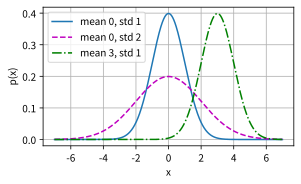

In [34]:
x = np.arange(-7, 7, 0.01)

params = [(0, 1), (0, 2), (3, 1)]
d2l.plot(x, [normal(x, mu, sigma) for mu, sigma in params], xlabel='x',
         ylabel='p(x)', figsize=(4.5, 2.5),
         legend=[f'mean {mu}, std {sigma}' for mu, sigma in params])

# 实现 Linear Regression

In [35]:
def synthetic_data(w, b, num_examples):  #@save
    """生成 y=Xw+b+噪声"""
    # pytorch 的 normal 返回的是高斯分布采样的结果，传入的是 mu, sigma, shape
    X = torch.normal(0, 1, (num_examples, len(w)))
    y = torch.matmul(X, w) + b
    y += torch.normal(0, 0.01, y.shape)
    return X, y.reshape((-1, 1))

In [36]:
true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = synthetic_data(true_w, true_b, 1000)
print('features:', features[0],'\nlabel:', labels[0])

features: tensor([-0.4987, -1.4931]) 
label: tensor([8.2815])


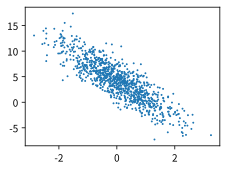

In [37]:
d2l.set_figsize()
d2l.plt.scatter(features[:,1].detach().numpy(), labels.detach().numpy(), 1)

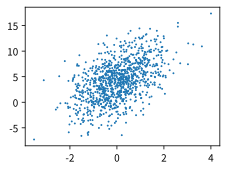

In [38]:
d2l.set_figsize()
d2l.plt.scatter(features[:, 0].detach().numpy(), labels.detach().numpy(), 1)

In [39]:
def data_iter(batch_size, features, labels):
    num_examples = len(features)
    indices = list(range(num_examples))
    random.shuffle(indices)
    for i in range(0, num_examples, batch_size):
        batch_indices = torch.tensor(indices[i:min(i+batch_size, num_examples)])
        yield features[batch_indices], labels[batch_indices]

In [40]:
batch_size = 10

for X, y in data_iter(batch_size, features, labels):
    print(X, '\n', y)
    break

tensor([[-0.9801,  0.9121],
        [ 1.8970,  0.2779],
        [ 1.6637,  0.5357],
        [-0.3325,  1.8433],
        [ 1.6103,  1.1892],
        [-1.4256, -1.3044],
        [-0.6869,  0.7018],
        [ 0.0048,  0.3036],
        [ 0.6506,  0.1452],
        [-0.0724, -0.1296]]) 
 tensor([[-0.8381],
        [ 7.0565],
        [ 5.6998],
        [-2.7283],
        [ 3.3816],
        [ 5.7848],
        [ 0.4632],
        [ 3.1863],
        [ 5.0115],
        [ 4.4984]])


In [41]:
w = torch.normal(0, 0.01, size=(2,1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)

In [42]:
# 定义模型，这样理解的话，模型其实就是一个函数/神经网络
def linreg(X, w, b): #@save
    """线性回归模型"""
    return torch.matmul(X, w) + b

def squared_loss(y_hat, y): #@save
    """均方损失"""
    return (y_hat - y.reshape(y_hat.shape)) ** 2 / 2

def sgd(params, lr, batch_size): #@save
    """小批量随即梯度下降"""
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size
            param.grad.zero_()

In [43]:
# 训练
lr = 0.03
num_epochs = 3
net = linreg
loss = squared_loss

for epoch in range(num_epochs):
    for X, y in data_iter(batch_size, features, labels):
        l = loss(net(X, w, b), y)
        
        l.sum().backward()
        sgd([w, b], lr, batch_size)
    
    with torch.no_grad():
        train_l = loss(net(features, w, b), labels)
        print(f'epoch {epoch + 1}, loss {float(train_l.mean()):f}')

print(f'w的估计误差：{true_w - w.reshape(true_w.shape)}')
print(f'b的估计误差：{true_b - b}')

epoch 1, loss 0.040880
epoch 2, loss 0.000168
epoch 3, loss 0.000053
w的估计误差：tensor([-0.0002, -0.0007], grad_fn=<SubBackward0>)
b的估计误差：tensor([0.0007], grad_fn=<RsubBackward1>)


In [44]:
# 线性回归的 pytorch 实现
import numpy as np
import torch
from torch.utils import data
from d2l import torch as d2l


# 生成数据集
true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = d2l.synthetic_data(true_w, true_b, 1000)

# 读取数据集
def load_array(data_arrays, batch_size, is_train=True): #@save
    """构造一个 pytorch 数据迭代器"""
    dataset = data.TensorDataset(*data_arrays)
    return data.DataLoader(dataset, batch_size, shuffle=is_train)

batch_size = 10
data_iter = load_array((features, labels), batch_size)

next(iter(data_iter))


[tensor([[ 1.0106, -2.8300],
         [-0.5362, -1.6800],
         [-0.0155, -0.2928],
         [ 0.1002, -0.4282],
         [-0.1590,  0.7039],
         [-0.0113, -0.7751],
         [-1.7089, -0.6107],
         [ 1.4704, -1.2545],
         [ 1.0667,  0.2838],
         [ 1.3981, -0.1289]]),
 tensor([[15.8613],
         [ 8.8247],
         [ 5.1896],
         [ 5.8504],
         [ 1.4923],
         [ 6.8125],
         [ 2.8586],
         [11.3995],
         [ 5.3773],
         [ 7.4539]])]

In [45]:
# 定义模型， nn 是神经网络的缩写
from torch import nn

# Sequential 类将多个层串联在一起，当给定输入数据时，Sequential 实例将数据传入到第一层，然后将第一层的输出作为第二层的输入，以此类推
net = nn.Sequential(nn.Linear(2, 1))

# 初始化模型参数
net[0].weight.data.normal_(0, 0.01)
net[0].bias.data.fill_(0)

tensor([0.])

In [46]:
# 定义损失函数
loss = nn.MSELoss()

# 定义优化算法
trainer = torch.optim.SGD(net.parameters(), lr=0.03)

In [47]:
# 训练
num_epochs = 3
for epoch in range(num_epochs):
    for X, y in data_iter:
        l = loss(net(X), y)
        trainer.zero_grad()
        l.backward()
        trainer.step()
    l=loss(net(features), labels)
    print(f'epoch {epoch + 1}, loss{l:f}')

w = net[0].weight.data
print(f'w的估计误差：{true_w - w.reshape(true_w.shape)}')
print(f'b的估计误差：{true_b - b}')

epoch 1, loss0.000235
epoch 2, loss0.000113
epoch 3, loss0.000109
w的估计误差：tensor([0.0003, 0.0003])
b的估计误差：tensor([0.0007], grad_fn=<RsubBackward1>)
